# 03 — Comparación de modelos en igualdad de condiciones
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/03_comparacion_equitativa.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

> Notebook creado después de la retroalimentación de la Segunda entrega (noviembre de 2026).

En la Segunda entrega solo Random Forest tuvo **pesos de clase** y **ajuste de hiperparámetros**; el árbol, AdaBoost y
Gradient Boosting quedaron con valores fijos y sin tratar el desbalance. Así, la conclusión "Random Forest es el más
robusto frente al desbalance" mezclaba el efecto del algoritmo con el efecto de esas dos ventajas.

Este notebook corrige eso (secciones **7.3–7.4** del enunciado) y, para la Entrega final (8.1), compara los **nueve
modelos del artículo** de Koshti et al. (2025) en las mismas condiciones:

| Condición (igual para los 9 modelos) | Cómo se aplica |
|---|---|
| Pesos de clase balanceados | `class_weight='balanced'` (Regresión Logística, SVM, Árbol, Random Forest, LightGBM); `sample_weight` balanceado calculado dentro de `fit` (AdaBoost, Gradient Boosting, XGBoost; ver `src/modelos_balanceados.py`); probabilidades a priori iguales (Naïve Bayes) |
| Ajuste de hiperparámetros | GridSearchCV con malla propia de cada modelo |
| Estimación del desempeño | CV anidada 5 × 3 |
| Datos, partición, Pipeline y pliegues | Idénticos para todos |

La métrica para elegir es la **balanced accuracy** (la misma de las entregas anteriores).

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA, FIGS, TABLES = ROOT / "data", ROOT / "figuras", ROOT / "resultados"
for d in (DATA, FIGS, TABLES):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto encontrada:", ROOT.name)

Raíz del proyecto encontrada: ml2-proyecto-riesgo-crediticio


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (balanced_accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)
from src.modelos_balanceados import AdaBoostBalanceado, GradientBoostingBalanceado, XGBoostBalanceado

plt.style.use("seaborn-v0_8-whitegrid")
ruta = DATA / "credito_colombia_simulado.csv"
if not ruta.exists():  # si no se ejecutó el notebook 01, se genera aquí
    from src.simulacion_credito import generar_dataset_credito_colombia
    generar_dataset_credito_colombia(6000, SEED).to_csv(ruta, index=False)
df = pd.read_csv(ruta)
print(df.shape, f"mora = {df.incumple.mean():.2%}")

(6000, 11) mora = 8.50%


## 1. Partición y flujo (idénticos al notebook 02)
Misma partición estratificada 80/20 y mismo Pipeline `SimpleImputer(median) → StandardScaler → modelo`, que se ajusta
solo con datos de entrenamiento en cada pliegue. Los pesos de AdaBoost, Gradient Boosting y XGBoost se calculan
**dentro** de `fit`, con la proporción de clases del pliegue de entrenamiento, así que tampoco hay fuga por ese lado.

In [3]:
X, y = df.drop(columns="incumple"), df["incumple"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

def make_pipe(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("classifier", model)])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)       # GridSearch final
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)     # CV anidada: interna
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1) # CV anidada: externa (la misma para todos)
print(f"Train: {len(X_train)} | Test: {len(X_test)} | mora en ambos: {y_train.mean():.2%} / {y_test.mean():.2%}")

Train: 4800 | Test: 1200 | mora en ambos: 8.50% / 8.50%


## 2. Modelos y mallas de hiperparámetros
Cada malla cubre los parámetros que controlan la complejidad de cada modelo (ver la explicación de cada uno en el
informe). Random Forest usa la misma malla de la Segunda entrega.

| Modelo | Hiperparámetros explorados |
|---|---|
| Regresión Logística | regularización C {0,01; 0,1; 1; 10} |
| Naïve Bayes (gaussiano) | suavizado de varianza {1e-9, 1e-7, 1e-5} |
| SVM (kernel RBF) | C {0,1; 1; 10} × gamma {scale; 0,01; 0,1} |
| Árbol | profundidad máxima {3, 5, 8, sin límite} × mínimo de registros por hoja {1, 10, 30} |
| Random Forest | árboles {100, 200} × profundidad {6, 8, 12} × mínimo para dividir {2, 5} × peso {balanced, balanced_subsample} |
| AdaBoost | árboles {100, 200, 400} × tasa de aprendizaje {0,25; 0,5; 1,0} (tocones de 1 nivel) |
| Gradient Boosting | árboles {100, 200, 400} × tasa de aprendizaje {0,02; 0,05; 0,1} × profundidad {1, 2, 3} |
| XGBoost | árboles {100, 300} × tasa de aprendizaje {0,05; 0,1} × profundidad {2, 3, 4} |
| LightGBM | árboles {100, 300} × tasa de aprendizaje {0,05; 0,1} × hojas por árbol {7, 15, 31} |

El SVM no estima probabilidades; para el AUC se usa su puntaje de decisión (`decision_function`), que ordena a los
clientes igual que una probabilidad.

In [4]:
candidatos = {
    "Regresión Logística": (
        LogisticRegression(class_weight="balanced", max_iter=2000),
        {"classifier__C": [0.01, 0.1, 1, 10]}),
    "Naïve Bayes": (
        GaussianNB(priors=[0.5, 0.5]),
        {"classifier__var_smoothing": [1e-9, 1e-7, 1e-5]}),
    "SVM": (
        SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
        {"classifier__C": [0.1, 1, 10], "classifier__gamma": ["scale", 0.01, 0.1]}),
    "Árbol de Decisión": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"classifier__max_depth": [3, 5, 8, None], "classifier__min_samples_leaf": [1, 10, 30]}),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED),
        {"classifier__n_estimators": [100, 200], "classifier__max_depth": [6, 8, 12],
         "classifier__min_samples_split": [2, 5], "classifier__class_weight": ["balanced", "balanced_subsample"]}),
    "AdaBoost": (
        AdaBoostBalanceado(random_state=SEED),
        {"classifier__n_estimators": [100, 200, 400], "classifier__learning_rate": [0.25, 0.5, 1.0]}),
    "Gradient Boosting": (
        GradientBoostingBalanceado(random_state=SEED),
        {"classifier__n_estimators": [100, 200, 400], "classifier__learning_rate": [0.02, 0.05, 0.1],
         "classifier__max_depth": [1, 2, 3]}),
    "XGBoost": (
        XGBoostBalanceado(random_state=SEED, n_jobs=1),
        {"classifier__n_estimators": [100, 300], "classifier__learning_rate": [0.05, 0.1],
         "classifier__max_depth": [2, 3, 4]}),
    "LightGBM": (
        LGBMClassifier(class_weight="balanced", random_state=SEED, n_jobs=1, verbose=-1),
        {"classifier__n_estimators": [100, 300], "classifier__learning_rate": [0.05, 0.1],
         "classifier__num_leaves": [7, 15, 31]}),
}

def puntaje(modelo, X):
    # Probabilidad de mora; para el SVM, su puntaje de decisión (sirve igual para el AUC)
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

## 3. Validación cruzada anidada (estimación honesta del desempeño)
En cada uno de los 5 pliegues externos se ejecuta un GridSearch interno (3 pliegues) solo con la parte de
entrenamiento de ese pliegue, y el modelo elegido se evalúa en el pliegue externo, que la búsqueda nunca vio.
Los pliegues externos son los mismos para todos los modelos, así que las diferencias se pueden comparar pliegue a pliegue.

In [5]:
anidada, por_pliegue, params_pliegue = [], {}, {}
for nombre, (modelo, malla) in candidatos.items():
    busqueda = GridSearchCV(make_pipe(modelo), malla, cv=inner, scoring="balanced_accuracy", n_jobs=-1)
    res = cross_validate(busqueda, X_train, y_train, cv=outer, scoring=["balanced_accuracy", "recall"],
                         return_estimator=True)
    por_pliegue[nombre] = res["test_balanced_accuracy"]
    params_pliegue[nombre] = [e.best_params_ for e in res["estimator"]]
    anidada.append({"Modelo": nombre,
                    "CV anidada Bal. Acc (media)": res["test_balanced_accuracy"].mean(),
                    "CV anidada Bal. Acc (desv)": res["test_balanced_accuracy"].std(),
                    "CV anidada Recall (media)": res["test_recall"].mean()})

tabla_anidada = pd.DataFrame(anidada).sort_values("CV anidada Bal. Acc (media)", ascending=False).round(4)
tabla_anidada

,Modelo,CV anidada Bal. Acc (media),CV anidada Bal. Acc (desv),CV anidada Recall (media)
0,Regresión Logística,0.8924,0.0082,0.9020
2,SVM,0.8912,0.0049,0.9142
4,Random Forest,0.8909,0.0109,0.9094
8,LightGBM,0.8908,0.0096,0.9020
7,XGBoost,0.8905,0.0102,0.9021
6,Gradient Boosting,0.8878,0.0066,0.8922
5,AdaBoost,0.8797,0.0154,0.8750
3,Árbol de Decisión,0.8572,0.0155,0.8727
1,Naïve Bayes,0.7835,0.0245,0.9902


### 3.1 Comparación pliegue a pliegue
Diferencia de cada modelo frente al mejor en cada pliegue externo. Si las diferencias cambian de signo entre pliegues
o son menores que la desviación entre pliegues, los modelos no se distinguen con estos datos.

,Regresión Logística,Naïve Bayes,SVM,Árbol de Decisión,Random Forest,AdaBoost,Gradient Boosting,XGBoost,LightGBM
Pliegue 1,0.8876,0.7367,0.8886,0.8371,0.8869,0.8534,0.8848,0.8954,0.8909
Pliegue 2,0.8925,0.7902,0.8936,0.8821,0.8980,0.8970,0.8937,0.9070,0.8942
Pliegue 3,0.8819,0.7864,0.8829,0.8471,0.8718,0.8733,0.8836,0.8765,0.8730
Pliegue 4,0.8933,0.8083,0.8939,0.8652,0.9032,0.8834,0.8973,0.8883,0.8937
Pliegue 5,0.9065,0.7957,0.8970,0.8547,0.8947,0.8913,0.8796,0.8853,0.9021


Diferencia frente a Regresión Logística (negativo = peor que Regresión Logística):


,Naïve Bayes,SVM,Árbol de Decisión,Random Forest,AdaBoost,Gradient Boosting,XGBoost,LightGBM
Pliegue 1,-0.1509,0.0010,-0.0505,-0.0007,-0.0342,-0.0028,0.0078,0.0033
Pliegue 2,-0.1023,0.0011,-0.0104,0.0055,0.0045,0.0012,0.0145,0.0017
Pliegue 3,-0.0955,0.0010,-0.0348,-0.0101,-0.0086,0.0017,-0.0054,-0.0089
Pliegue 4,-0.0850,0.0006,-0.0281,0.0099,-0.0099,0.0040,-0.0050,0.0004
Pliegue 5,-0.1108,-0.0095,-0.0518,-0.0118,-0.0152,-0.0269,-0.0212,-0.0044
Media,-0.1089,-0.0012,-0.0351,-0.0014,-0.0127,-0.0046,-0.0019,-0.0016
Desv.,0.0253,0.0047,0.0171,0.0095,0.0140,0.0127,0.0138,0.0050


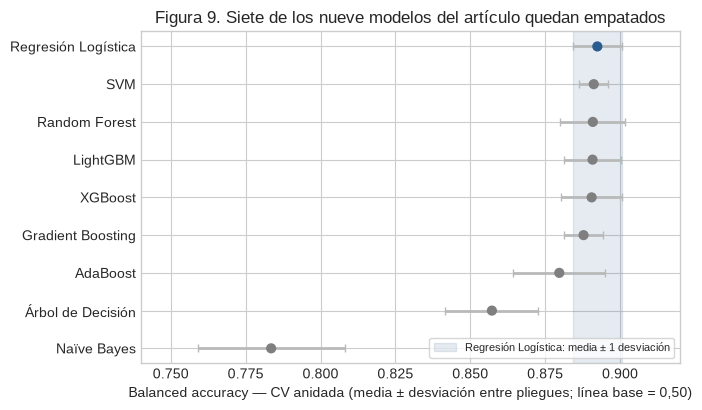

In [6]:
pliegues = pd.DataFrame(por_pliegue, index=[f"Pliegue {k}" for k in range(1, 6)]).round(4)
mejor = tabla_anidada.iloc[0]["Modelo"]
dif = pliegues.sub(pliegues[mejor], axis=0).drop(columns=mejor)
display(pliegues)
print(f"Diferencia frente a {mejor} (negativo = peor que {mejor}):")
display(pd.concat([dif, dif.agg(["mean", "std"]).rename(index={"mean": "Media", "std": "Desv."})]).round(4))

orden = tabla_anidada.sort_values("CV anidada Bal. Acc (media)")
fig, ax = plt.subplots(figsize=(7, 4.2))
colores_fig = ["#2b5c8f" if m == mejor else "#7f7f7f" for m in orden["Modelo"]]
ax.errorbar(orden["CV anidada Bal. Acc (media)"], orden["Modelo"], xerr=orden["CV anidada Bal. Acc (desv)"],
            fmt="none", ecolor="#b9b9b9", elinewidth=2, capsize=3)
ax.scatter(orden["CV anidada Bal. Acc (media)"], orden["Modelo"], color=colores_fig, zorder=3, s=40)
m0 = tabla_anidada.iloc[0]
ax.axvspan(m0["CV anidada Bal. Acc (media)"] - m0["CV anidada Bal. Acc (desv)"],
           m0["CV anidada Bal. Acc (media)"] + m0["CV anidada Bal. Acc (desv)"],
           color="#2b5c8f", alpha=0.12, label=f"{mejor}: media ± 1 desviación")
ax.set_xlim(0.74, 0.92)
ax.legend(loc="lower right", fontsize=8, frameon=True)
ax.set(xlabel="Balanced accuracy — CV anidada (media ± desviación entre pliegues; línea base = 0,50)",
       title="Figura 9. Siete de los nueve modelos del artículo quedan empatados")
plt.tight_layout(); plt.savefig(FIGS / "fig9_nueve_modelos_cv_anidada.png", dpi=300); plt.show()

### 3.2 Estabilidad de los hiperparámetros elegidos en cada pliegue externo

In [7]:
for nombre, lista in params_pliegue.items():
    print(f"\n{nombre}")
    display(pd.DataFrame(lista).rename(columns=lambda c: c.replace("classifier__", "")))


Regresión Logística


,C
0,10.0
1,1.0
2,0.1
3,1.0
4,1.0



Naïve Bayes


,var_smoothing
0,0.00001
1,0.00001
2,0.00001
3,0.00001
4,0.00001



SVM


,C,gamma
0,1.0,0.01
1,1.0,0.01
2,1.0,0.01
3,10.0,0.01
4,0.1,0.01


... (8 outputs left out)


XGBoost


,learning_rate,max_depth,n_estimators
0,0.10,2,100
1,0.05,2,100
2,0.10,3,100
3,0.05,2,300
4,0.10,2,100



LightGBM


,learning_rate,n_estimators,num_leaves
0,0.05,100,7
1,0.05,100,7
2,0.05,100,7
3,0.05,100,7
4,0.05,100,7


## 4. Ajuste final y evaluación en el conjunto de prueba
Cada modelo se ajusta con GridSearch (5 pliegues) sobre todo el entrenamiento y se evalúa **una sola vez** en la
prueba, junto con la línea base.

In [8]:
finales, filas, scores = {}, [], {}

base = make_pipe(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
finales["Baseline (Mayoría)"] = base

for nombre, (modelo, malla) in candidatos.items():
    gs = GridSearchCV(make_pipe(modelo), malla, cv=cv5, scoring="balanced_accuracy", n_jobs=-1).fit(X_train, y_train)
    finales[nombre] = gs.best_estimator_
    print(f"{nombre:20s} mejores parámetros:",
          {k.replace("classifier__", ""): v for k, v in gs.best_params_.items()})

for nombre, modelo in finales.items():
    pred = modelo.predict(X_test)
    scores[nombre] = puntaje(modelo, X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append({"Modelo": nombre,
                  "Test Bal. Acc": balanced_accuracy_score(y_test, pred),
                  "Test Recall": recall_score(y_test, pred, zero_division=0),
                  "Test Precision": precision_score(y_test, pred, zero_division=0),
                  "Test F1": f1_score(y_test, pred, zero_division=0),
                  "Test ROC-AUC": roc_auc_score(y_test, scores[nombre]),
                  "Morosos detectados": f"{tp} de {tp + fn}", "Falsas alarmas": fp})

tabla3 = (pd.DataFrame(filas).merge(tabla_anidada, on="Modelo", how="left")
          [["Modelo", "CV anidada Bal. Acc (media)", "CV anidada Bal. Acc (desv)", "Test Bal. Acc", "Test Recall",
            "Test Precision", "Test F1", "Test ROC-AUC", "Morosos detectados", "Falsas alarmas"]])
tabla3.round(4).to_csv(TABLES / "tabla3_comparacion_equitativa.csv", index=False)
tabla3.round(4)

Regresión Logística  mejores parámetros: {'C': 0.1}
Naïve Bayes          mejores parámetros: {'var_smoothing': 1e-05}


SVM                  mejores parámetros: {'C': 0.1, 'gamma': 0.01}


Árbol de Decisión    mejores parámetros: {'max_depth': 5, 'min_samples_leaf': 10}


Random Forest        mejores parámetros: {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_split': 5, 'n_estimators': 100}


AdaBoost             mejores parámetros: {'learning_rate': 1.0, 'n_estimators': 100}


Gradient Boosting    mejores parámetros: {'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 400}


XGBoost              mejores parámetros: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}


LightGBM             mejores parámetros: {'learning_rate': 0.05, 'n_estimators': 100, 'num_leaves': 7}


,Modelo,CV anidada Bal. Acc (media),CV anidada Bal. Acc (desv),Test Bal. Acc,Test Recall,Test Precision,Test F1,Test ROC-AUC,Morosos detectados,Falsas alarmas
0,Baseline (Mayoría),NaN,NaN,0.5000,0.0000,0.0000,0.0000,0.5000,0 de 102,0
1,Regresión Logística,0.8924,0.0082,0.8994,0.9118,0.4286,0.5831,0.9628,93 de 102,124
2,Naïve Bayes,0.7835,0.0245,0.7911,0.9902,0.1840,0.3103,0.9506,101 de 102,448
3,SVM,0.8912,0.0049,0.8964,0.9412,0.3707,0.5319,0.9595,96 de 102,163
4,Árbol de Decisión,0.8572,0.0155,0.8573,0.8529,0.3640,0.5103,0.8747,87 de 102,152
5,Random Forest,0.8909,0.0109,0.8659,0.8529,0.3955,0.5404,0.9434,87 de 102,133
6,AdaBoost,0.8797,0.0154,0.8705,0.8529,0.4143,0.5577,0.9502,87 de 102,123
7,Gradient Boosting,0.8878,0.0066,0.8890,0.9020,0.4035,0.5576,0.9541,92 de 102,136
8,XGBoost,0.8905,0.0102,0.8588,0.8333,0.4009,0.5414,0.9501,85 de 102,127
9,LightGBM,0.8908,0.0096,0.8833,0.8824,0.4147,0.5643,0.9513,90 de 102,127


### 4.1 Antes y después de igualar las condiciones
Balanced accuracy en prueba de cada modelo en la Segunda entrega (sin pesos ni ajuste, salvo Random Forest) frente a
este notebook.

,Segunda entrega,Igualdad de condiciones,Cambio
Árbol de Decisión,0.7278,0.8573,0.1295
Random Forest,0.8659,0.8659,0.0000
AdaBoost,0.7124,0.8705,0.1581
Gradient Boosting,0.7547,0.8890,0.1343


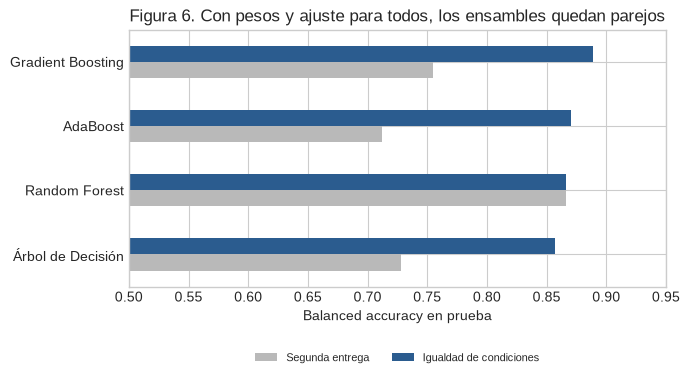

In [9]:
entrega2 = {"Árbol de Decisión": 0.7278, "Random Forest": 0.8659, "AdaBoost": 0.7124, "Gradient Boosting": 0.7547}
antes_despues = pd.DataFrame({
    "Segunda entrega": pd.Series(entrega2),
    "Igualdad de condiciones": tabla3.set_index("Modelo")["Test Bal. Acc"].reindex(list(entrega2)),
})
antes_despues["Cambio"] = antes_despues["Igualdad de condiciones"] - antes_despues["Segunda entrega"]
display(antes_despues.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
antes_despues[["Segunda entrega", "Igualdad de condiciones"]].plot(kind="barh", ax=ax, color=["#b9b9b9", "#2b5c8f"])
ax.set(xlim=(0.5, 0.95), xlabel="Balanced accuracy en prueba",
       title="Figura 6. Con pesos y ajuste para todos, los ensambles quedan parejos")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(FIGS / "fig6_antes_despues_igualdad.png", dpi=300); plt.show()

## 5. Importancia de variables por permutación (modelo con mejor CV anidada)
La importancia MDI de la Segunda entrega se calcula con los datos de entrenamiento y favorece a las variables
continuas. La **importancia por permutación** mide cuánto cae la balanced accuracy **en la prueba** cuando se
desordena una variable: si cae mucho, el modelo depende de ella.

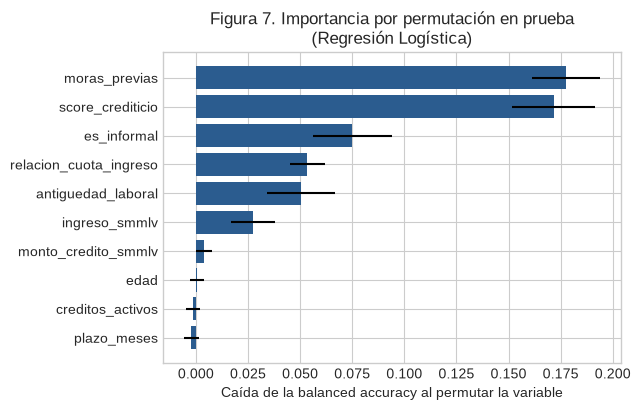

,media,desv
moras_previas,0.1777,0.0163
score_crediticio,0.1717,0.0199
es_informal,0.0750,0.0190
relacion_cuota_ingreso,0.0535,0.0083
antiguedad_laboral,0.0502,0.0163
ingreso_smmlv,0.0274,0.0107
monto_credito_smmlv,0.0039,0.0040
edad,0.0006,0.0033
creditos_activos,-0.0012,0.0034
plazo_meses,-0.0022,0.0037


In [10]:
elegido = tabla_anidada.iloc[0]["Modelo"]
perm = permutation_importance(finales[elegido], X_test, y_test, scoring="balanced_accuracy",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"media": perm.importances_mean, "desv": perm.importances_std},
                   index=X.columns).sort_values("media")
imp.round(4).to_csv(TABLES / "importancia_permutacion.csv")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(imp.index, imp["media"], xerr=imp["desv"], color="#2b5c8f")
ax.set(title=f"Figura 7. Importancia por permutación en prueba\n({elegido})",
       xlabel="Caída de la balanced accuracy al permutar la variable")
plt.tight_layout(); plt.savefig(FIGS / "fig7_importancia_permutacion.png", dpi=300); plt.show()
imp.sort_values("media", ascending=False).round(4)

## 6. ¿Dónde se equivoca el modelo? Errores por tipo de empleo
Se cruzan los errores del modelo elegido en la prueba con el segmento laboral del solicitante.

In [11]:
pred = finales[elegido].predict(X_test)
errores = pd.DataFrame({"segmento": np.where(X_test["es_informal"] == 1, "Informal", "Formal"),
                        "real": y_test.values, "pred": pred})
filas_seg = []
for seg, g in errores.groupby("segmento"):
    filas_seg.append({"Segmento": seg, "Solicitantes": len(g),
                      "Morosos reales": int((g.real == 1).sum()),
                      "Morosos detectados": int(((g.real == 1) & (g.pred == 1)).sum()),
                      "Morosos no detectados (FN)": int(((g.real == 1) & (g.pred == 0)).sum()),
                      "Falsas alarmas (FP)": int(((g.real == 0) & (g.pred == 1)).sum()),
                      "% de buenos clientes rechazados": round(100 * ((g.real == 0) & (g.pred == 1)).sum() / (g.real == 0).sum(), 1),
                      "% de solicitudes rechazadas": round(100 * (g.pred == 1).mean(), 1)})
resumen = pd.DataFrame(filas_seg).set_index("Segmento")
resumen

,Solicitantes,Morosos reales,Morosos detectados,Morosos no detectados (FN),Falsas alarmas (FP),% de buenos clientes rechazados,% de solicitudes rechazadas
Segmento,,,,,,,
Formal,519,1,0,1,0,0.0,0.0
Informal,681,101,93,8,124,21.4,31.9


## 7. Lectura

**1. Siete de los nueve modelos del artículo quedan empatados.** En la CV anidada, Regresión Logística (0,892 ± 0,008),
SVM (0,891 ± 0,005), Random Forest (0,891 ± 0,011), LightGBM (0,891 ± 0,010), XGBoost (0,891 ± 0,010), Gradient
Boosting (0,888 ± 0,007) y AdaBoost (0,880 ± 0,015) quedan a 0,012 o menos entre sí, y frente al mejor la diferencia
cambia de signo entre pliegues (Figura 9 y sección 3.1). Con estos datos no se puede afirmar que uno sea mejor. El árbol
individual (0,857) y Naïve Bayes (0,784) quedan por debajo en los cinco pliegues.

**2. Por qué un modelo lineal empata con los ensambles.** La mora se simuló con un logit (notebook 01): el riesgo es
una suma ponderada de las variables en escala logarítmica de odds, que es exactamente la forma que asume la Regresión
Logística. Los ensambles de árboles ganan cuando hay relaciones no lineales o interacciones que aprovechar, y aquí la
única no linealidad relevante es la relación cuota/ingreso. Es una diferencia de fondo con el artículo, cuyos datos
reales favorecen a los ensambles; se discute como limitación de la simulación.

**3. Corrige la conclusión de la Segunda entrega.** La ventaja de Random Forest venía sobre todo de que era el único
modelo con pesos de clase y ajuste: al darles las mismas condiciones, AdaBoost sube 0,16 de balanced accuracy en prueba,
Gradient Boosting 0,13 y el árbol 0,13 (Figura 6). Lo que importaba era tratar el desbalance, no el tipo de ensamble.

**4. Coincidencias con el artículo.** Como en Koshti et al. (2025), Naïve Bayes y el árbol individual son los modelos
más débiles (en el dataset alemán: 72,0 % y 74,3 % de accuracy), y los ensambles superan al árbol. Naïve Bayes falla
porque supone variables independientes, y aquí la informalidad conecta al ingreso, el score, la antigüedad y las moras.

**5. Variables relevantes.** La importancia por permutación en prueba del modelo con mejor CV anidada (Regresión
Logística) ubica primero a `moras_previas` y `score_crediticio`, luego `es_informal`, `relacion_cuota_ingreso` y
`antiguedad_laboral`. Las variables de control que no entran en la simulación de la mora (`edad`, `plazo_meses`,
`creditos_activos`) tienen importancia nula: el modelo no aprende ruido.

**6. Los errores recaen en los informales.** El modelo no rechaza a ningún solicitante formal y rechaza al 32 % de los
informales; las 124 falsas alarmas son todas de informales que sí pagan (21 % de los informales al día). Es consecuencia
de la mora formal casi nula de la simulación (notebook 01) y del riesgo social planteado en la Primera entrega: excluir
del crédito a población informal solvente.

**7. Selección del modelo final.** Se hace en el notebook 05, con esta comparación como base.